# 01. SELIC — Análise da Política Monetária Brasileira

## SELIC Meta • SELIC Over • Banco Central • PostgreSQL


Este notebook inicia a camada analítica do projeto após a validação
dos dados realizada em: ```00.auditoria_dados.ipynb```  

O fluxo operacional esperado é:

```text
IBGE/SIDRA ──┐
             ├── pipelines ──> PostgreSQL
BCB/SGS ─────┘                     │
                                   v
                           00.auditoria_dados
                                   │
                                   v
                               01.selic
```

Este notebook assume que:

- os pipelines já foram executados;
- as tabelas estão atualizadas;
- a auditoria foi concluída;
- os dados estão aptos para análise.

Ele NÃO executa pipelines e NÃO altera o banco de dados.

---


### Objetivos



1. Entender a SELIC Meta e a SELIC Over.
2. Examinar a cobertura histórica das séries.
3. Analisar a evolução da política monetária.
4. Identificar movimentos de alta e queda da Meta.
5. Explorar a série diária da SELIC Over.
6. Preparar representações mensais das séries.
7. Criar uma ponte para a futura análise entre juros e inflação.

### 1. O que é a SELIC?


A SELIC ocupa posição central na política monetária brasileira.

Movimentos na taxa de juros influenciam, direta ou indiretamente:

- condições de crédito;
- consumo;
- investimento;
- atividade econômica;
- expectativas;
- preços de ativos;
- câmbio;
- inflação.

Para este projeto, distinguimos duas séries relacionadas, mas com
significados diferentes:

```text
    SELIC Meta →    objetivo da política monetária
    SELIC Over →    taxa efetivamente observada
```

Essa distinção será importante quando relacionarmos juros e inflação.

#### 1.1 SELIC Meta



A SELIC Meta representa a meta para a taxa Selic definida pelo Copom
em suas decisões de política monetária.

No projeto utilizamos: ```BCB/SGS 432```

Ela representa principalmente o sinal da política monetária:

```text
aumento da Meta →       política monetária mais restritiva
redução da Meta →       política monetária menos restritiva
```

A interpretação econômica concreta depende também do contexto de inflação,
expectativas e atividade econômica.

#### 1.2 SELIC Over

A SELIC Over representa uma taxa efetivamente observada associada ao
funcionamento diário do mercado de reservas e do sistema Selic.

No projeto utilizamos: ```BCB/SGS 11```

### 2. Configuração do ambiente

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 3. Importações

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.4f}".format)

### 4. Carregar as séries do PostgreSQL

Diferentemente da versão antiga deste notebook, os pipelines NÃO são
executados aqui.

A camada analítica apenas consome os dados já persistidos.

In [3]:
selic_meta = pd.read_sql(
    """
    SELECT
        date,
        value,
        series_id
    FROM bcb.selic_meta
    ORDER BY date;
    """,
    engine,
)

selic_over = pd.read_sql(
    """
    SELECT
        date,
        value,
        series_id
    FROM bcb.selic_over
    ORDER BY date;
    """,
    engine,
)

##### 4.1 Padronizar datas

Antes de qualquer operação temporal, normalizamos explicitamente o tipo
das datas.

In [5]:
selic_meta["date"] = pd.to_datetime(selic_meta["date"])
selic_over["date"] = pd.to_datetime(selic_over["date"])

selic_meta = (
    selic_meta
        .sort_values("date")
        .reset_index(drop=True)
)
selic_over = (
    selic_over
        .sort_values("date")
        .reset_index(drop=True)
)

### 5. Cobertura histórica

Antes da interpretação econômica, queremos saber qual período está
efetivamente disponível para cada série.

In [6]:
resumo_series = pd.DataFrame(
    [
        {
            "serie": "SELIC Meta",
            "inicio": selic_meta["date"].min(),
            "fim": selic_meta["date"].max(),
            "observacoes": len(selic_meta),
        },
        {
            "serie": "SELIC Over",
            "inicio": selic_over["date"].min(),
            "fim": selic_over["date"].max(),
            "observacoes": len(selic_over),
        },
    ]
)

resumo_series

,serie,inicio,fim,observacoes
0,SELIC Meta,2000-01-01,2026-11-04,9805
1,SELIC Over,2000-01-03,2026-09-25,6715


### 6. Observações mais recentes

In [8]:
print("SELIC Meta")
display(
    selic_meta.tail(5)
)

print("\nSELIC Over")
display(
    selic_over.tail(5)
)

SELIC Meta


,date,value,series_id
9800,2026-10-31,13.7500,432
9801,2026-11-01,13.7500,432
9802,2026-11-02,13.7500,432
9803,2026-11-03,13.7500,432
9804,2026-11-04,13.7500,432



SELIC Over


,date,value,series_id
6710,2026-09-21,0.0508,11
6711,2026-09-22,0.0508,11
6712,2026-09-23,0.0508,11
6713,2026-09-24,0.0508,11
6714,2026-09-25,0.0508,11


### 7. Estatísticas descritivas

As estatísticas devem ser interpretadas com cautela porque as séries
atravessam regimes monetários muito distintos ao longo do tempo.

In [9]:
print("SELIC Meta")

display(
    selic_meta["value"].describe().to_frame()
)

SELIC Meta


,value
count,9805.0000
mean,12.4431
std,4.8342
min,2.0000
25%,9.2500
50%,12.2500
75%,15.0000
max,26.5000


In [10]:
print("SELIC Over")

display(
    selic_over["value"].describe().to_frame()
)

SELIC Over


,value
count,6715.0000
mean,0.0459
std,0.0171
min,0.0075
25%,0.0347
50%,0.0456
75%,0.0551
max,0.0929


---

## PARTE I — SELIC META



### 8. Evolução histórica da SELIC Meta

Como a Meta permanece constante entre alterações, um gráfico em degraus
representa melhor sua natureza do que uma linha interpolada visualmente.

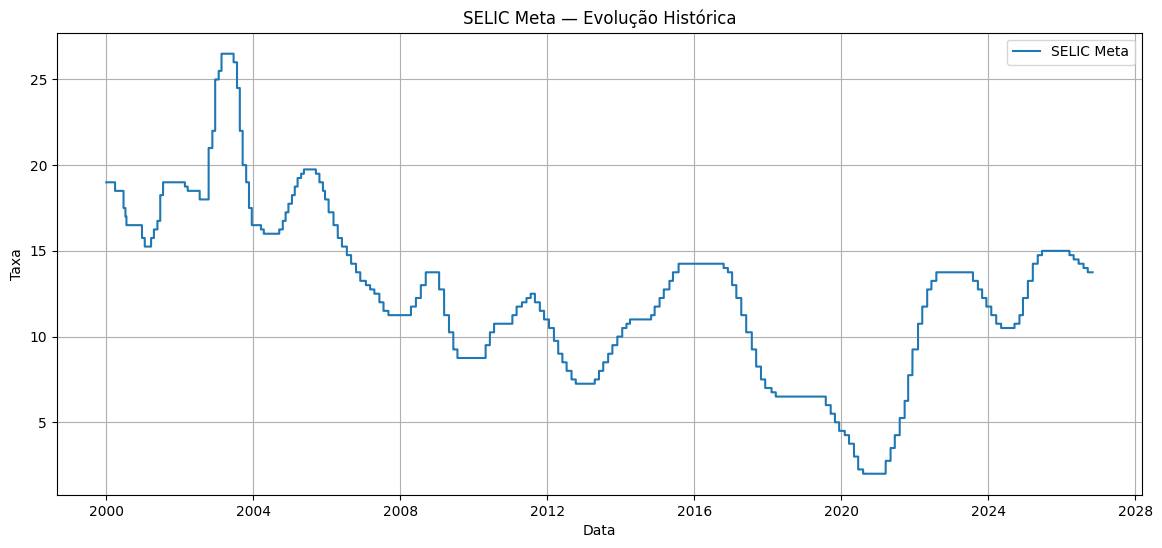

In [11]:
plt.figure(figsize=(14, 6))

plt.step(
    selic_meta["date"],
    selic_meta["value"],
    where="post",
    label="SELIC Meta",
)

plt.title("SELIC Meta — Evolução Histórica")
plt.xlabel("Data")
plt.ylabel("Taxa")
plt.grid(True)
plt.legend()

plt.show()

### 9. Identificar alterações da Meta

Se a série possui observações repetidas entre decisões, podemos reduzir
a análise aos pontos em que o valor efetivamente muda.

In [15]:
mudancas_meta = selic_meta.loc[
    selic_meta["value"].ne(
        selic_meta["value"].shift()
    )
].copy()

mudancas_meta["delta"] = (
    mudancas_meta["value"].diff()
)

mudancas_meta.tail(10)

,date,value,series_id,delta
9112,2024-12-12,12.2500,432,1.0000
9161,2025-01-30,13.2500,432,1.0000
9210,2025-03-20,14.2500,432,1.0000
9259,2025-05-08,14.7500,432,0.5000
9301,2025-06-19,15.0000,432,0.2500
9574,2026-03-19,14.7500,432,-0.2500
9616,2026-04-30,14.5000,432,-0.2500
9665,2026-06-18,14.2500,432,-0.2500
9714,2026-08-06,14.0000,432,-0.2500
9756,2026-09-17,13.7500,432,-0.2500


### 10. Direção das alterações

Classificamos cada alteração observada em:

```text
delta > 0  -> alta
delta < 0  -> queda
```

A primeira observação não possui comparação anterior.

In [17]:
mudancas_meta["direcao"] = np.select(
    [
        mudancas_meta["delta"] > 0,
        mudancas_meta["delta"] < 0,
    ],
    [
        "alta",
        "queda",
    ],
    default="inicial",
)

mudancas_meta.tail(10)

,date,value,series_id,delta,direcao
9112,2024-12-12,12.2500,432,1.0000,alta
9161,2025-01-30,13.2500,432,1.0000,alta
9210,2025-03-20,14.2500,432,1.0000,alta
9259,2025-05-08,14.7500,432,0.5000,alta
9301,2025-06-19,15.0000,432,0.2500,alta
9574,2026-03-19,14.7500,432,-0.2500,queda
9616,2026-04-30,14.5000,432,-0.2500,queda
9665,2026-06-18,14.2500,432,-0.2500,queda
9714,2026-08-06,14.0000,432,-0.2500,queda
9756,2026-09-17,13.7500,432,-0.2500,queda


### 11. Quantidade de movimentos

In [18]:
mudancas_meta["direcao"].value_counts()

direcao
queda      84
alta       66
inicial     1
Name: count, dtype: int64

### 12. Magnitude das mudanças da Meta

In [19]:
mudancas_validas = mudancas_meta[
    mudancas_meta["delta"].notna()
].copy()

mudancas_validas["delta"].describe()

count   150.0000
mean     -0.0350
std       0.7874
min      -2.5000
25%      -0.5000
50%      -0.2500
75%       0.5000
max       3.0000
Name: delta, dtype: float64

#### Maiores aumentos observados

In [20]:
mudancas_validas.nlargest(
    10,
    "delta",
)[
    ["date", "value", "delta", "direcao"]
]

,date,value,delta,direcao
1018,2002-10-15,21.0000,3.0000,alta
1083,2002-12-19,25.0000,3.0000,alta
537,2001-06-21,18.2500,1.5000,alta
7971,2021-10-28,7.7500,1.5000,alta
8013,2021-12-09,9.2500,1.5000,alta
8069,2022-02-03,10.7500,1.5000,alta
1055,2002-11-21,22.0000,1.0000,alta
1146,2003-02-20,26.5000,1.0000,alta
7887,2021-08-05,5.2500,1.0000,alta
7936,2021-09-23,6.2500,1.0000,alta


#### Maiores reduções observadas

In [23]:
mudancas_validas.nsmallest(
    10,
    "delta",
)[
    ["date", "value", "delta", "direcao"]
]

,date,value,delta,direcao
1328,2003-08-21,22.0000,-2.5000,queda
1356,2003-09-18,20.0000,-2.0000,queda
1300,2003-07-24,24.5000,-1.5000,queda
1419,2003-11-20,17.5000,-1.5000,queda
3358,2009-03-12,11.2500,-1.5000,queda
172,2000-06-21,17.5000,-1.0000,queda
1391,2003-10-23,19.0000,-1.0000,queda
1447,2003-12-18,16.5000,-1.0000,queda
3309,2009-01-22,12.7500,-1.0000,queda
3407,2009-04-30,10.2500,-1.0000,queda


### 13. Visualizar mudanças da política monetária

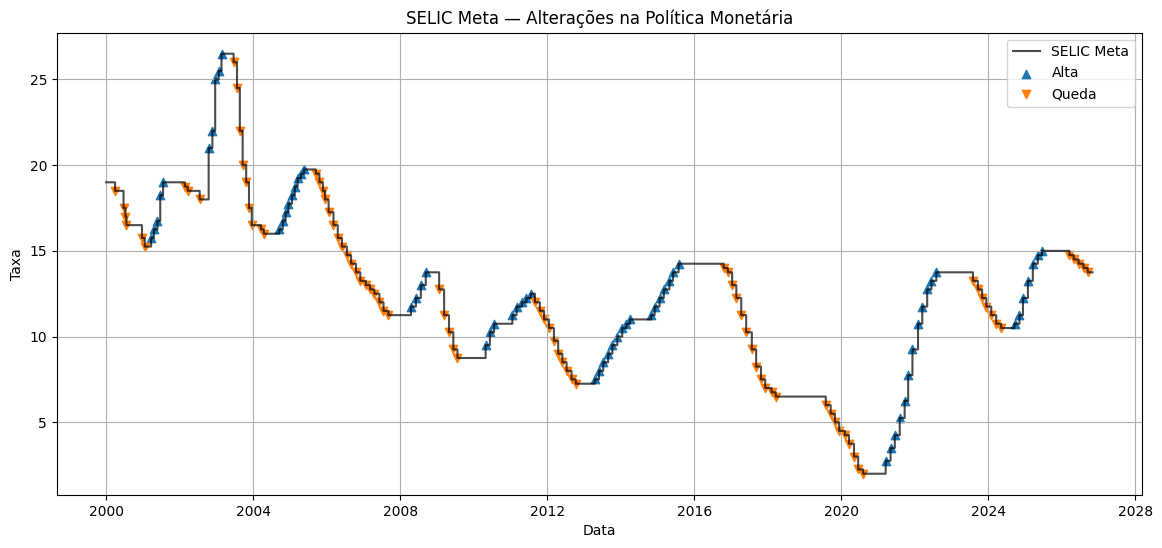

In [24]:
plt.figure(figsize=(14, 6))

plt.step(
    selic_meta["date"],
    selic_meta["value"],
    where="post",
    color="black",
    alpha=0.7,
    label="SELIC Meta",
)

altas = mudancas_meta[
    mudancas_meta["direcao"] == "alta"
]

quedas = mudancas_meta[
    mudancas_meta["direcao"] == "queda"
]

plt.scatter(
    altas["date"],
    altas["value"],
    label="Alta",
    marker="^",
)

plt.scatter(
    quedas["date"],
    quedas["value"],
    label="Queda",
    marker="v",
)

plt.title("SELIC Meta — Alterações na Política Monetária")
plt.xlabel("Data")
plt.ylabel("Taxa")
plt.grid(True)
plt.legend()

plt.show()

### 14. Variação da Meta ao longo do tempo

O gráfico abaixo mostra a magnitude das alterações, e não o nível da taxa.

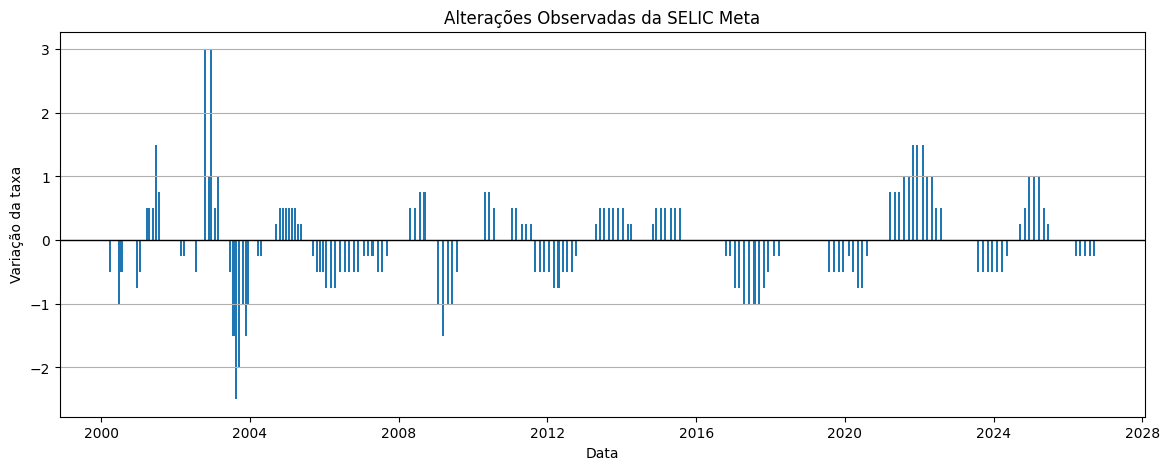

In [25]:
plt.figure(figsize=(14, 5))

plt.bar(
    mudancas_validas["date"],
    mudancas_validas["delta"],
    width=20,
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title("Alterações Observadas da SELIC Meta")
plt.xlabel("Data")
plt.ylabel("Variação da taxa")
plt.grid(True, axis="y")

plt.show()

---

## PARTE II — SELIC OVER



### 15. Evolução histórica da SELIC Over

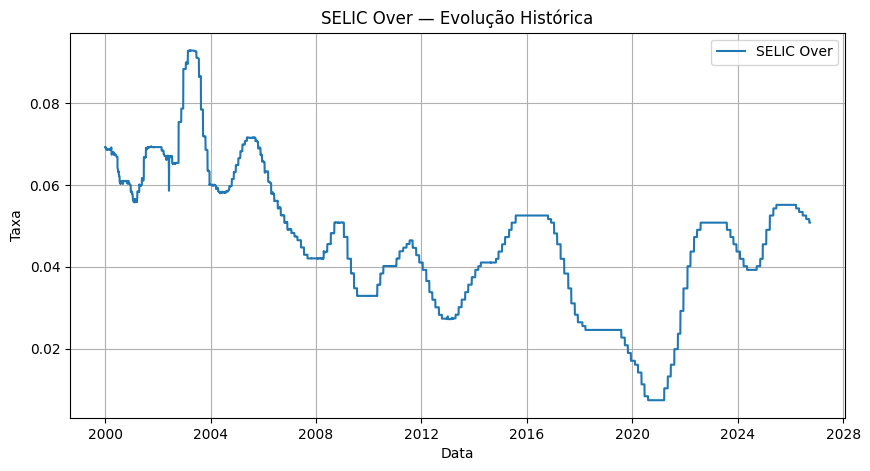

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    selic_over["date"],
    selic_over["value"],
    label="SELIC Over",
)

plt.title("SELIC Over — Evolução Histórica")
plt.xlabel("Data")
plt.ylabel("Taxa")
plt.grid(True)
plt.legend()

plt.show()

### 16. Distribuição da SELIC Over

A distribuição histórica mistura diferentes regimes monetários.
Portanto, este gráfico é descritivo e não implica estacionariedade.

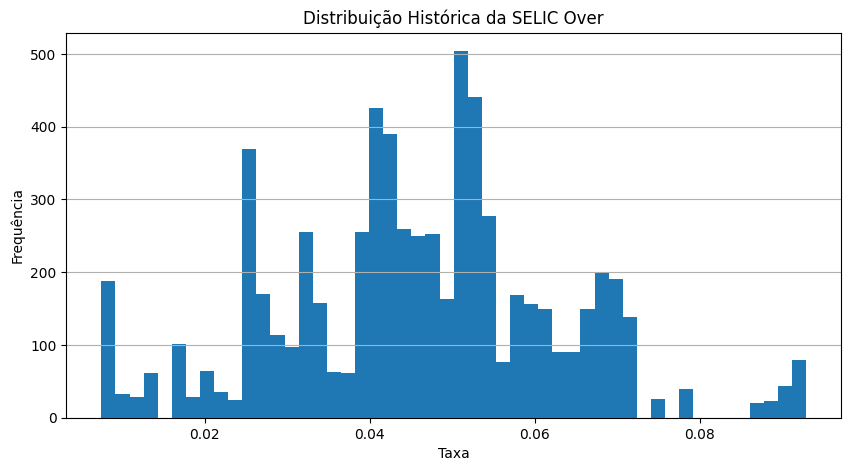

In [27]:
plt.figure(figsize=(10, 5))

plt.hist(
    selic_over["value"].dropna(),
    bins=50,
)

plt.title("Distribuição Histórica da SELIC Over")
plt.xlabel("Taxa")
plt.ylabel("Frequência")
plt.grid(True, axis="y")

plt.show()

### 17. Frequência temporal da SELIC Over

A série não necessariamente apresenta observações em todos os dias
corridos. Examinar o intervalo entre registros ajuda a compreender
sua estrutura temporal.

In [33]:
intervalos_over = (
    selic_over["date"]
    .diff()
    .dt.days
)

intervalos_over.describe()

count   6714.0000
mean       1.4540
std        0.8694
min        1.0000
25%        1.0000
50%        1.0000
75%        1.0000
max        5.0000
Name: date, dtype: float64

In [34]:
intervalos_over.value_counts().sort_index().head(15)

date
1.0000    5200
2.0000     120
3.0000    1285
4.0000      78
5.0000      31
Name: count, dtype: int64

---

## PARTE III — COMPARABILIDADE ENTRE META E OVER



### 18. Frequências diferentes



Temos duas séries com estruturas temporais diferentes:

```text
SELIC Meta →        muda apenas quando o nível da meta é alterado
SELIC Over →        observações de frequência mais alta
```

Para relacioná-las ao IPCA posteriormente, precisaremos construir representações mensais.

### 19. SELIC Meta mensal

Para cada mês, utilizamos o último valor observado e propagamos a Meta
quando necessário.

Essa representação será importante para o futuro merge com o IPCA,
que possui frequência mensal.

In [36]:
selic_meta_mensal = (
    selic_meta
        .set_index("date")["value"]
        .resample("MS")
        .last()
        .ffill()
        .rename("selic_meta")
        .to_frame()
)

selic_meta_mensal.tail(8)

,selic_meta
date,
2026-04-01,14.5000
2026-05-01,14.5000
2026-06-01,14.2500
2026-07-01,14.2500
2026-08-01,14.0000
2026-09-01,13.7500
2026-10-01,13.7500
2026-11-01,13.7500


### 20. SELIC Over mensal

Neste momento ainda não escolhemos uma única agregação da SELIC Over
para modelagem.

Calculamos diferentes estatísticas mensais:

- média;
- mediana;
- mínimo;
- máximo;
- último valor observado.

Posteriormente poderemos decidir qual representação faz maior sentido
econômico e estatístico para cada modelo.

In [37]:
selic_over_mensal = (
    selic_over
        .set_index("date")["value"]
        .resample("MS")
        .agg(
            ["mean", "median", "min", "max", "last"]
    )
)

selic_over_mensal = (
    selic_over_mensal
        .rename(
            columns={
                "mean": "over_media",
                "median": "over_mediana",
                "min": "over_min",
                "max": "over_max",
                "last": "over_ultimo",
            }
        )
)

selic_over_mensal.tail(8)

,over_media,over_mediana,over_min,over_max,over_ultimo
date,,,,,
2026-02-01,0.0551,0.0551,0.0551,0.0551,0.0551
2026-03-01,0.0548,0.0551,0.0543,0.0551,0.0543
2026-04-01,0.0542,0.0543,0.0534,0.0543,0.0534
2026-05-01,0.0534,0.0534,0.0534,0.0534,0.0534
2026-06-01,0.0530,0.0534,0.0525,0.0534,0.0525
2026-07-01,0.0525,0.0525,0.0525,0.0525,0.0525
2026-08-01,0.0518,0.0517,0.0517,0.0525,0.0517
2026-09-01,0.0513,0.0517,0.0508,0.0517,0.0508


### 21. Base mensal conjunta de juros

In [39]:
selic_mensal = (
    selic_meta_mensal
        .join(
            selic_over_mensal,
            how="inner",
        )
        .reset_index()
)

selic_mensal.tail(8)

,date,selic_meta,over_media,over_mediana,over_min,over_max,over_ultimo
313,2026-02-01,15.0000,0.0551,0.0551,0.0551,0.0551,0.0551
314,2026-03-01,14.7500,0.0548,0.0551,0.0543,0.0551,0.0543
315,2026-04-01,14.5000,0.0542,0.0543,0.0534,0.0543,0.0534
316,2026-05-01,14.5000,0.0534,0.0534,0.0534,0.0534,0.0534
317,2026-06-01,14.2500,0.0530,0.0534,0.0525,0.0534,0.0525
318,2026-07-01,14.2500,0.0525,0.0525,0.0525,0.0525,0.0525
319,2026-08-01,14.0000,0.0518,0.0517,0.0517,0.0525,0.0517
320,2026-09-01,13.7500,0.0513,0.0517,0.0508,0.0517,0.0508


### 22. Cobertura da base mensal

In [40]:
pd.DataFrame(
    {
        "inicio": [selic_mensal["date"].min()],
        "fim": [selic_mensal["date"].max()],
        "meses": [len(selic_mensal)],
    }
)

,inicio,fim,meses
0,2000-01-01,2026-09-01,321


### 23. Comparação visual em frequência mensal

Neste gráfico ainda NÃO tentamos converter mecanicamente as unidades
das séries.

O objetivo é observar sua evolução temporal após alinhamento mensal.

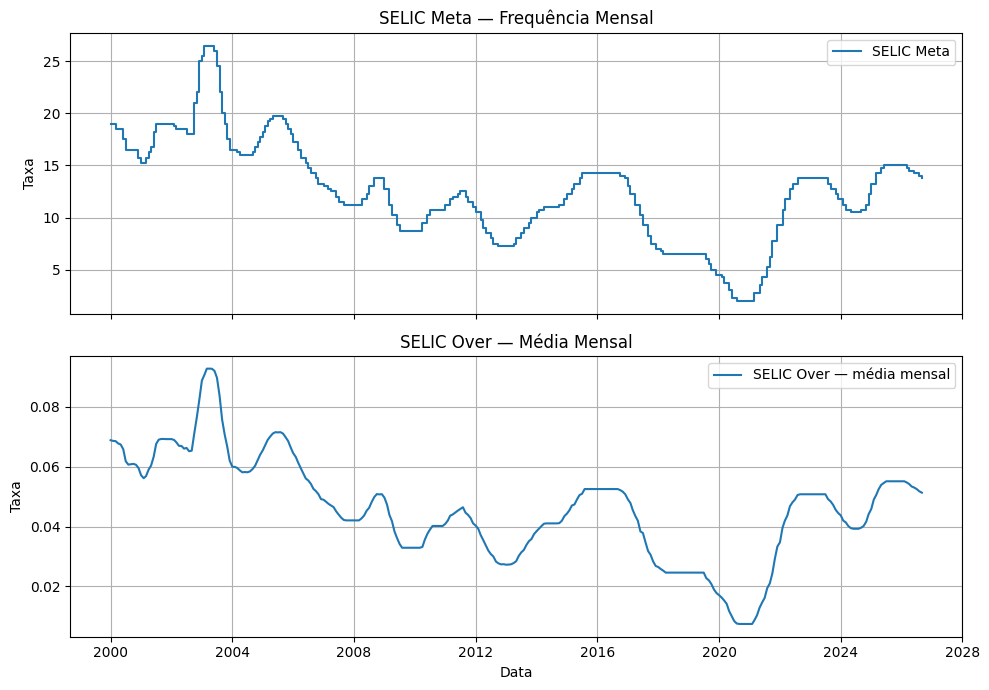

In [42]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(10, 7),
    sharex=True,
)

axes[0].step(
    selic_mensal["date"],
    selic_mensal["selic_meta"],
    where="post",
    label="SELIC Meta",
)

axes[0].set_title(
    "SELIC Meta — Frequência Mensal"
)
axes[0].set_ylabel("Taxa")
axes[0].grid(True)
axes[0].legend()


axes[1].plot(
    selic_mensal["date"],
    selic_mensal["over_media"],
    label="SELIC Over — média mensal",
)

axes[1].set_title(
    "SELIC Over — Média Mensal"
)
axes[1].set_xlabel("Data")
axes[1].set_ylabel("Taxa")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

---

## PARTE IV — PREPARAÇÃO PARA A ANÁLISE ECONÔMICA



### 24. Regime monetário simplificado

A diferença da Meta mensal pode ser usada para identificar meses de:

- aperto monetário;
- afrouxamento monetário;
- manutenção.

Essa classificação é apenas descritiva neste notebook.

In [55]:
selic_mensal["delta_meta"] = (
    selic_mensal["selic_meta"].diff()
)

selic_mensal["regime_meta"] = np.select(
    [
        selic_mensal["delta_meta"] > 0,
        selic_mensal["delta_meta"] < 0,
    ],
    [
        "aperto",
        "afrouxamento",
    ],
    default="manutencao",
)

selic_mensal.tail(24)

,date,selic_meta,over_media,over_mediana,over_min,over_max,over_ultimo,delta_meta,regime_meta
297,2024-10-01,10.7500,0.0402,0.0402,0.0402,0.0402,0.0402,0.0000,manutencao
298,2024-11-01,11.2500,0.0416,0.0420,0.0402,0.0420,0.0420,0.5000,aperto
299,2024-12-01,12.2500,0.0442,0.0455,0.0420,0.0455,0.0455,1.0000,aperto
300,2025-01-01,13.2500,0.0458,0.0455,0.0455,0.0490,0.0490,1.0000,aperto
301,2025-02-01,13.2500,0.0490,0.0490,0.0490,0.0490,0.0490,0.0000,manutencao
302,2025-03-01,14.2500,0.0505,0.0490,0.0490,0.0525,0.0525,1.0000,aperto
303,2025-04-01,14.2500,0.0525,0.0525,0.0525,0.0525,0.0525,0.0000,manutencao
304,2025-05-01,14.7500,0.0539,0.0543,0.0525,0.0543,0.0543,0.5000,aperto
305,2025-06-01,15.0000,0.0546,0.0543,0.0543,0.0551,0.0551,0.2500,aperto
306,2025-07-01,15.0000,0.0551,0.0551,0.0551,0.0551,0.0551,0.0000,manutencao


### 25. Frequência dos regimes

In [56]:
selic_mensal["regime_meta"].value_counts()

regime_meta
manutencao      172
afrouxamento     83
aperto           66
Name: count, dtype: int64

### 26. Visualizar períodos de alteração mensal da Meta

In [70]:
alteracoes_mensais = selic_mensal[
    selic_mensal["delta_meta"].ne(0)
    & selic_mensal["delta_meta"].notna()
].copy()

alteracoes_mensais.tail(20)

,date,selic_meta,over_media,over_mediana,over_min,over_max,over_ultimo,delta_meta,regime_meta
271,2022-08-01,13.7500,0.0506,0.0508,0.0490,0.0508,0.0508,0.5000,aperto
283,2023-08-01,13.2500,0.0492,0.0490,0.0490,0.0508,0.0490,-0.5000,afrouxamento
284,2023-09-01,12.7500,0.0484,0.0490,0.0473,0.0490,0.0473,-0.5000,afrouxamento
286,2023-11-01,12.2500,0.0456,0.0455,0.0455,0.0473,0.0455,-0.5000,afrouxamento
287,2023-12-01,11.7500,0.0445,0.0437,0.0437,0.0455,0.0437,-0.5000,afrouxamento
289,2024-02-01,11.2500,0.0420,0.0420,0.0420,0.0420,0.0420,-0.5000,afrouxamento
290,2024-03-01,10.7500,0.0414,0.0420,0.0402,0.0420,0.0402,-0.5000,afrouxamento
292,2024-05-01,10.5000,0.0395,0.0393,0.0393,0.0402,0.0393,-0.2500,afrouxamento
296,2024-09-01,10.7500,0.0396,0.0393,0.0393,0.0402,0.0402,0.2500,aperto
298,2024-11-01,11.2500,0.0416,0.0420,0.0402,0.0420,0.0420,0.5000,aperto


### 27. Observações para futura modelagem

Ao relacionarmos juros e inflação, devemos tomar alguns cuidados.



#### 27.1 Frequência

O IPCA é mensal, enquanto as séries monetárias possuem frequência maior.

Precisaremos definir uma representação mensal coerente da política monetária.



#### 27.2 Defasagens

A política monetária não afeta a inflação instantaneamente.

Portanto, modelos futuros deverão considerar estruturas como:

$$
IPCA_t = f(
SELIC_{t-1},
SELIC_{t-2},
\ldots,
SELIC_{t-k}
)
$$

além das próprias defasagens da inflação.



#### 27.3 Endogeneidade

Uma associação positiva contemporânea entre SELIC e inflação não significa
que juros maiores provoquem inflação maior.

O Banco Central pode elevar juros justamente em resposta a uma inflação
elevada ou a expectativas de inflação.

Isto cria uma relação simultânea que precisa ser considerada na
interpretação dos modelos.



#### 27.4 Vazamento temporal

Para machine learning, uma feature só poderá ser usada se estivesse
disponível no momento da previsão.

Portanto:

```text
informação futura →           não pode entrar em X_t
```

Esse princípio será central na construção do dataset de modelagem.

### 28. Dataset mensal preliminar

In [71]:
selic_features = selic_mensal[
    [
        "date",
        "selic_meta",
        "over_media",
        "over_mediana",
        "over_min",
        "over_max",
        "over_ultimo",
        "delta_meta",
        "regime_meta",
    ]
].copy()

selic_features.tail(12)

,date,selic_meta,over_media,over_mediana,over_min,over_max,over_ultimo,delta_meta,regime_meta
309,2025-10-01,15.0000,0.0551,0.0551,0.0551,0.0551,0.0551,0.0000,manutencao
310,2025-11-01,15.0000,0.0551,0.0551,0.0551,0.0551,0.0551,0.0000,manutencao
311,2025-12-01,15.0000,0.0551,0.0551,0.0551,0.0551,0.0551,0.0000,manutencao
312,2026-01-01,15.0000,0.0551,0.0551,0.0551,0.0551,0.0551,0.0000,manutencao
313,2026-02-01,15.0000,0.0551,0.0551,0.0551,0.0551,0.0551,0.0000,manutencao
314,2026-03-01,14.7500,0.0548,0.0551,0.0543,0.0551,0.0543,-0.2500,afrouxamento
315,2026-04-01,14.5000,0.0542,0.0543,0.0534,0.0543,0.0534,-0.2500,afrouxamento
316,2026-05-01,14.5000,0.0534,0.0534,0.0534,0.0534,0.0534,0.0000,manutencao
317,2026-06-01,14.2500,0.0530,0.0534,0.0525,0.0534,0.0525,-0.2500,afrouxamento
318,2026-07-01,14.2500,0.0525,0.0525,0.0525,0.0525,0.0525,0.0000,manutencao


#### Importante

`selic_features` ainda NÃO é o dataset final de machine learning.

Neste notebook ele serve apenas para demonstrar quais representações
mensais podem ser extraídas das séries monetárias.

A construção formal de features ocorrerá posteriormente em uma camada
própria do projeto.

### 29. Conclusões

A análise da SELIC estabelece a primeira dimensão macroeconômica que
posteriormente será relacionada ao comportamento da inflação.



#### Principais pontos

##### SELIC Meta

Representa o objetivo da política monetária e possui comportamento
caracterizado por períodos de manutenção intercalados com movimentos
de alta ou queda.

##### SELIC Over

Possui frequência mais alta e representa uma dimensão efetivamente
observada das condições monetárias.

##### Frequência mensal

Como o IPCA possui frequência mensal, construímos representações mensais
das séries de juros.

Isso cria uma base conceitual para análises posteriores:

```text
SELIC
  │
  ├── nível
  ├── variação
  ├── regime monetário
  └── agregações mensais
           │
           v
         IPCA
```

---



### Próxima etapa

O próximo notebook será: ```02.ipca.ipynb```

Nele aplicaremos a mesma separação:

```text
00 →        qualidade dos dados
01 →        análise da SELIC
02 →        análise do IPCA
```

Posteriormente, os dois blocos serão integrados em:

```text
IPCA + SELIC
      ↓
análise de defasagens
      ↓
modelos estatísticos
      ↓
machine learning
      ↓
forecasting
```